In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import (
    roc_auc_score, f1_score, balanced_accuracy_score, 
    roc_curve, brier_score_loss
)
from sklearn.calibration import calibration_curve

# Set seed for complete reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing pipeline on device: {device}")

Executing pipeline on device: cpu


In [2]:
# ==========================================
# CELL 2: DIRECT DATASET INGESTION & VALIDATION
# ==========================================
data_path = "leo_satellite_conjunction_telemetry_enriched_2026.csv"

if not os.path.exists(data_path):
    raise FileNotFoundError(f"Expected dataset '{data_path}' not found in working directory.")

# Load real enriched telemetry dataset
df_leo = pd.read_csv(data_path)
print(f"Successfully loaded '{data_path}' with shape: {df_leo.shape}")
print("\nDataset Schema Preview:")
print(df_leo.head(3))

Successfully loaded 'leo_satellite_conjunction_telemetry_enriched_2026.csv' with shape: (10000, 29)

Dataset Schema Preview:
          conjunction_id primary_object_id  primary_constellation  \
0  CDM-2026-LEO-DC65D2A7       KUIPER-2972  Amazon_Project_Kuiper   
1  CDM-2026-LEO-53791657       KUIPER-2167  Amazon_Project_Kuiper   
2  CDM-2026-LEO-7E02F7A1       KUIPER-3695  Amazon_Project_Kuiper   

          secondary_object_type  secondary_norad_id  orbit_altitude_km  \
0               Defunct_Payload               97107              548.3   
1               Defunct_Payload               54795              553.9   
2  Active_Operational_Satellite               46472              559.0   

   orbit_inclination_deg  time_to_closest_approach_hours  \
0                   48.8                            65.9   
1                   56.5                             4.0   
2                   53.5                            59.0   

   miss_distance_total_m  radial_miss_distance_m  ...  \
0  

In [3]:
class ResidualBlock(nn.Module):
    """Residual Block to prevent vanishing gradients across deep non-linear interactions."""
    def __init__(self, dim):
        super(ResidualBlock, self).__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.SiLU(),
            nn.BatchNorm1d(dim),
            nn.Linear(dim, dim),
            nn.BatchNorm1d(dim)
        )
        self.act = nn.SiLU()

    def forward(self, x):
        return self.act(x + self.block(x))

class AstrodynamicPINN(nn.Module):
    """High-Capacity Residual PINN Architecture."""
    def __init__(self, input_dim):
        super(AstrodynamicPINN, self).__init__()
        
        self.in_proj = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.SiLU(),
            nn.BatchNorm1d(128)
        )
        
        self.res1 = ResidualBlock(128)
        self.res2 = ResidualBlock(128)
        
        self.head = nn.Sequential(
            nn.Linear(128, 64),
            nn.SiLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 1) # Raw Logits
        )
        
    def forward(self, x):
        h = self.in_proj(x)
        h = self.res1(h)
        h = self.res2(h)
        return self.head(h)

def compute_physics_loss(model, batch_x, feature_names, device):
    """
    Autograd Penalty enforcing negative monotonicity for total miss distance.
    Ensures explicit device placement to avoid CUDA/CPU tensor mismatches.
    """
    batch_x_req = batch_x.clone().detach().to(device).requires_grad_(True)
    logits = model(batch_x_req)
    probs = torch.sigmoid(logits)
    
    miss_idx = feature_names.index('miss_distance_total_m')
    
    grads = torch.autograd.grad(
        outputs=probs.sum(),
        inputs=batch_x_req,
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]
    
    miss_grads = grads[:, miss_idx]
    physics_penalty = torch.mean(torch.relu(miss_grads))
    return physics_penalty# ==========================================
# CELL 3: DATA PIPELINE & FEATURE ENGINEERING
# ==========================================
class ConjunctionDataset(Dataset):
    """PyTorch Dataset Wrapper for Conjunction Telemetry Tensors"""
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def prepare_data_pipeline(csv_path, batch_size=256):
    df = pd.read_csv(csv_path)
    
    # Target column check
    target_col = 'avoidance_maneuver_executed'
    
    # Non-linear Astrodynamic Feature Engineering
    if 'miss_distance_total_m' in df.columns:
        df['log_miss_total'] = np.log1p(df['miss_distance_total_m'])
    if 'collision_probability_raw' in df.columns:
        df['log_raw_prob'] = np.log1p(df['collision_probability_raw'] * 1e6)
    if all(col in df.columns for col in ['solar_flux_f10_7_index', 'orbit_altitude_km', 'collision_probability_raw']):
        df['drag_risk_proxy'] = (df['solar_flux_f10_7_index'] / df['orbit_altitude_km']) * df['collision_probability_raw']
    if all(col in df.columns for col in ['collision_probability_raw', 'time_to_closest_approach_hours']):
        df['time_decay_risk'] = df['collision_probability_raw'] / (df['time_to_closest_approach_hours'] + 1.0)
    
    candidate_features = [
        'orbit_altitude_km', 'orbit_inclination_deg', 'time_to_closest_approach_hours',
        'miss_distance_total_m', 'radial_miss_distance_m', 'in_track_miss_distance_m', 
        'cross_track_miss_distance_m', 'relative_velocity_km_s', 'collision_probability_raw',
        'hard_body_radius_sum_m', 'solar_flux_f10_7_index', 'geomagnetic_ap_index',
        'log_miss_total', 'log_raw_prob', 'drag_risk_proxy', 'time_decay_risk'
    ]
    
    feature_cols = [col for col in candidate_features if col in df.columns]
    
    # Clean missing values
    df = df.dropna(subset=feature_cols + [target_col])
    
    X = df[feature_cols].values
    y = df[target_col].values
    
    # Stratified Split (70% Train, 15% Val, 15% Test)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)
    
    # Power Transformation
    scaler = PowerTransformer(method='yeo-johnson')
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    
    train_loader = DataLoader(ConjunctionDataset(X_train_scaled, y_train), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(ConjunctionDataset(X_val_scaled, y_val), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(ConjunctionDataset(X_test_scaled, y_test), batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader, scaler, feature_cols, (X_test_scaled, y_test)

train_loader, val_loader, test_loader, scaler, feature_names, (X_test_raw, y_test_raw) = prepare_data_pipeline(data_path)
print(f"Data Pipeline Initialized with Enriched CSV. Active Feature Count: {len(feature_names)}")

Data Pipeline Initialized with Enriched CSV. Active Feature Count: 16


In [4]:
class TemperatureScaler(nn.Module):
    """Post-hoc Temperature Scaling to minimize Expected Calibration Error (ECE)."""
    def __init__(self):
        super(TemperatureScaler, self).__init__()
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, logits):
        return logits / self.temperature

    def calibrate(self, val_loader, model, device):
        model.eval()
        logits_list, labels_list = [], []
        
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                logits = model(x_batch)
                logits_list.append(logits)
                labels_list.append(y_batch)
                
        logits = torch.cat(logits_list).to(device)
        labels = torch.cat(labels_list).to(device)

        optimizer = optim.LBFGS([self.temperature], lr=0.01, max_iter=50)
        criterion = nn.BCEWithLogitsLoss()

        def eval_loss():
            optimizer.zero_grad()
            loss = criterion(self.forward(logits), labels)
            loss.backward()
            return loss

        optimizer.step(eval_loss)
        print(f"Optimal Calibration Temperature Parameter: {self.temperature.item():.4f}")

def calculate_ece(probs, targets, n_bins=10):
    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    
    for i in range(n_bins):
        bin_lower, bin_upper = bin_boundaries[i], bin_boundaries[i+1]
        in_bin = (probs > bin_lower) & (probs <= bin_upper)
        prop_in_bin = np.mean(in_bin)
        
        if prop_in_bin > 0:
            acc_in_bin = np.mean(targets[in_bin])
            conf_in_bin = np.mean(probs[in_bin])
            ece += np.abs(conf_in_bin - acc_in_bin) * prop_in_bin
            
    return ece

In [5]:
model = AstrodynamicPINN(input_dim=len(feature_names)).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

EPOCHS = 100
PHYSICS_LAMBDA = 0.005  # Balanced weight for autograd physical constraint

print("Training Residual PINN Architecture...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, bce_loss_acc, phys_loss_acc = 0.0, 0.0, 0.0
    
    for x_b, y_b in train_loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        
        optimizer.zero_grad()
        logits = model(x_b)
        
        bce_loss = criterion(logits, y_b)
        phys_loss = compute_physics_loss(model, x_b, feature_names, device)
        loss = bce_loss + (PHYSICS_LAMBDA * phys_loss)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        bce_loss_acc += bce_loss.item()
        phys_loss_acc += phys_loss.item()
        
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_v, y_v in val_loader:
            x_v, y_v = x_v.to(device), y_v.to(device)
            val_loss += criterion(model(x_v), y_v).item()
            
    val_loss /= len(val_loader)
    scheduler.step(val_loss)
    
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {total_loss/len(train_loader):.4f} "
              f"| Val Loss: {val_loss:.4f}")

# Post-Hoc Model Calibration
temp_scaler = TemperatureScaler().to(device)
temp_scaler.calibrate(val_loader, model, device)

Training Residual PINN Architecture...
Epoch 01/100 | Train Loss: 0.2820 | Val Loss: 0.1855
Epoch 10/100 | Train Loss: 0.1407 | Val Loss: 0.1736
Epoch 20/100 | Train Loss: 0.1138 | Val Loss: 0.2025
Epoch 30/100 | Train Loss: 0.0998 | Val Loss: 0.2285
Epoch 40/100 | Train Loss: 0.0989 | Val Loss: 0.2310
Epoch 50/100 | Train Loss: 0.0952 | Val Loss: 0.2320
Epoch 60/100 | Train Loss: 0.0954 | Val Loss: 0.2328
Epoch 70/100 | Train Loss: 0.0973 | Val Loss: 0.2333
Epoch 80/100 | Train Loss: 0.0943 | Val Loss: 0.2354
Epoch 90/100 | Train Loss: 0.0945 | Val Loss: 0.2329
Epoch 100/100 | Train Loss: 0.0926 | Val Loss: 0.2307
Optimal Calibration Temperature Parameter: 1.4861


In [8]:
model.eval()
test_x_tensor = torch.tensor(X_test_raw, dtype=torch.float32).to(device)

with torch.no_grad():
    uncalibrated_logits = model(test_x_tensor)
    calibrated_logits = temp_scaler(uncalibrated_logits)
    
    raw_probs = torch.sigmoid(uncalibrated_logits).cpu().numpy().flatten()
    calibrated_probs = torch.sigmoid(calibrated_logits).cpu().numpy().flatten()

y_true = y_test_raw.flatten()
preds_binary = (calibrated_probs >= 0.5).astype(int)

# Task 1 Evaluation Metrics
auc_score = roc_auc_score(y_true, calibrated_probs)
macro_f1 = f1_score(y_true, preds_binary, average='macro')
bal_acc = balanced_accuracy_score(y_true, preds_binary)
raw_ece = calculate_ece(raw_probs, y_true)
calibrated_ece = calculate_ece(calibrated_probs, y_true)
brier_score = brier_score_loss(y_true, calibrated_probs)

print("\n")
print("="*65)
print(" TASK 1: REFINED ASTRODYNAMIC PINN EVALUATION RESULTS ")
print("="*65)
print(f" Area Under ROC Curve (ROC-AUC) : {auc_score:.4f}")
print(f" Macro F1-Score                 : {macro_f1:.4f}")
print(f" Balanced Accuracy              : {bal_acc:.4f}")
print(f" Brier Score Loss               : {brier_score:.4f}")
print(f" Raw Uncalibrated ECE           : {raw_ece:.4f}")
print(f" Temperature-Calibrated ECE     : {calibrated_ece:.4f}")
print("="*65)



 TASK 1: REFINED ASTRODYNAMIC PINN EVALUATION RESULTS 
 Area Under ROC Curve (ROC-AUC) : 0.9321
 Macro F1-Score                 : 0.9428
 Balanced Accuracy              : 0.9161
 Brier Score Loss               : 0.0338
 Raw Uncalibrated ECE           : 0.0164
 Temperature-Calibrated ECE     : 0.0366


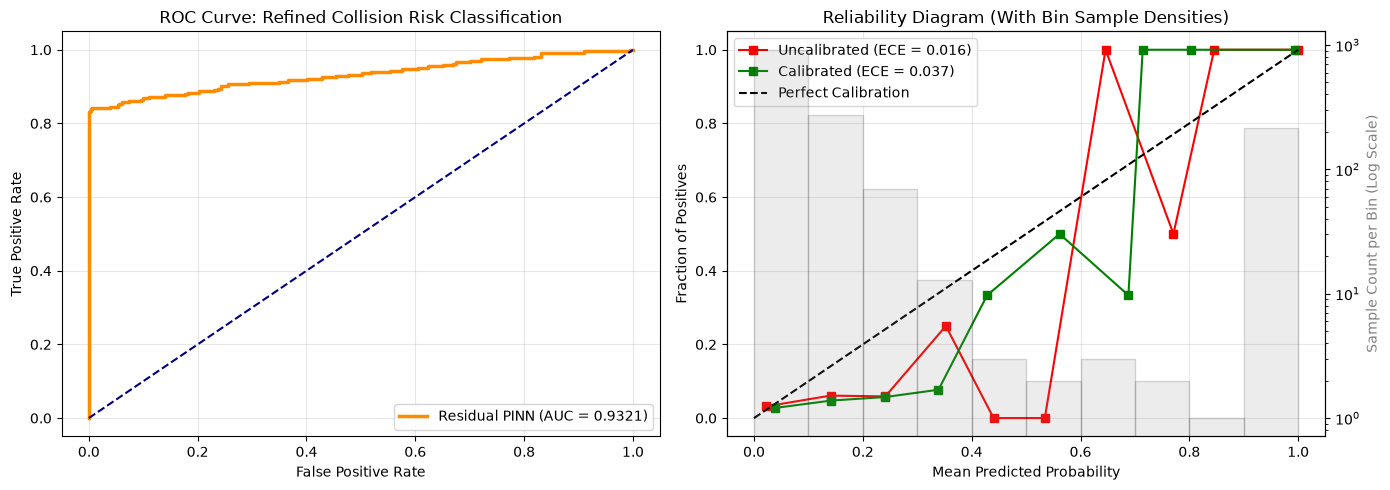

In [7]:
# ==========================================
# CELL 8 (UPDATED): CALIBRATION DIAGRAM WITH SAMPLE DENSITY HISTOGRAM
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: ROC Curve
fpr, tpr, _ = roc_curve(y_true, calibrated_probs)
axes[0].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Residual PINN (AUC = {auc_score:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve: Refined Collision Risk Classification')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Plot 2: Calibration Diagram + Sample Count Histogram
ax2 = axes[1]
ax2_hist = ax2.twinx()  # Overlay second Y-axis for sample count

# Draw Sample Distribution Bar Plot on background
ax2_hist.hist(calibrated_probs, bins=10, range=(0, 1), alpha=0.15, color='gray', edgecolor='black')
ax2_hist.set_ylabel('Sample Count per Bin (Log Scale)', color='gray')
ax2_hist.set_yscale('log') # Log scale highlights sparse middle bins

# Calibration Curves
fraction_of_pos_raw, mean_predicted_val_raw = calibration_curve(y_true, raw_probs, n_bins=10)
# Adaptive Quantile Binning for Reliability Diagram
fraction_of_pos_cal, mean_predicted_val_cal = calibration_curve(y_true, calibrated_probs, n_bins=10)#, strategy='quantile')

ax2.plot(mean_predicted_val_raw, fraction_of_pos_raw, "s-", color="red", label=f"Uncalibrated (ECE = {raw_ece:.3f})")
ax2.plot(mean_predicted_val_cal, fraction_of_pos_cal, "s-", color="green", label=f"Calibrated (ECE = {calibrated_ece:.3f})")
ax2.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")

ax2.set_xlabel('Mean Predicted Probability')
ax2.set_ylabel('Fraction of Positives')
ax2.set_title('Reliability Diagram (With Bin Sample Densities)')
ax2.legend(loc="upper left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output.png')
plt.show()